# 2026-10-14 Emily Ziraldo
# Updated version of NOVA Classification Prediction Code used for FLIP 2023
# Difference from previous version of code (file: forPublicUse_FLIP_NOVA_NLP.ipynb) is that the model was trained with manually validated NOVA classifications for both FLIP 2017 and FLIP 2020. 
# The prior code only used the FLIP 2017 data for training.

In [ ]:
import sys
print(sys.executable)

c:\Users\LabbeStaff\Desktop\Emily\flip2023_nova\nova2023_env\Scripts\python.exe


In [2]:
# Packages for modeling and data analysis

import sys
import numpy as np
import pandas as pd
import torch
import transformers

from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    roc_auc_score,
    mean_squared_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    roc_curve,
    auc,
    f1_score,
    precision_recall_fscore_support,
    log_loss,
    classification_report
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

transformers.logging.set_verbosity_error()

# Check environment
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Torch _utils:", hasattr(torch, "_utils"))

c:\Users\LabbeStaff\Desktop\Emily\flip2023_nova\nova2023_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
PyTorch: 2.11.0+cu128
Transformers: 5.15.0
Torch _utils: True


In [3]:
# Packages and settings for model performance and visualization

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 200

sns.set(
    rc={'figure.figsize': (4, 4)},
    style='ticks',
    font="Arial",
    font_scale=1
)

# 1. Train and Validate the Model Using FLIP2017 Data

In [4]:
# Import datasets
df2017 = pd.read_excel(
    "data/flip2017_14Aug2026.xlsx"
)

df2020 = pd.read_excel(
    "data/flip2020_14Aug2026.xlsx"
)

df2023 = pd.read_excel(
    "data/flip2023_14Aug2026.xlsx"
)

print("2017:", df2017.shape)
print("2020:", df2020.shape)
print("2023:", df2023.shape)

2017: (17693, 14)
2020: (48829, 14)
2023: (110581, 15)


In [5]:
# Clean 2017 data for model training
data2017 = df2017.copy()

# Look at the contents of the Ingredients and NOVA variables
print(df2017["Ingredients"].value_counts(dropna=False).sort_index())
print(df2017["NOVA"].value_counts(dropna=False).sort_index())

# Check the NOVA variable
print("NOVA values before cleaning:")
print(df2017["NOVA"].value_counts(dropna=False).sort_index())

# Check how many ingredients are missing
print("\nMissing Ingredients:")
print(df2017["Ingredients"].isna().sum())

# Look at a few example ingredient lists
print("\nExample ingredients before cleaning:")
display(df2017["Ingredients"].dropna().head(5))

# Keep products with ingredients and known NOVA classifications
data2017 = data2017.loc[
    data2017["Ingredients"].notna()
].copy()

data2017 = data2017.loc[
    data2017["NOVA"].notna()
].copy()

# Clean ingredients text
data2017["Ingredients"] = (
    data2017["Ingredients"]
    .astype(str) # convert all ingredients values to strings
    .str.replace(r"\s+", " ", regex=True) # clean up extra spaces and replace it with one space
    .str.strip() # remove whitespace from beginning and end of ingredient list
    .str.lower() # convert all letters to lowercase
)

# Convert NOVA to numeric
data2017["NOVA"] = pd.to_numeric(
    data2017["NOVA"],
    errors="coerce"
)

# Remove values that could not be converted to numeric
data2017 = data2017.loc[
    data2017["NOVA"].notna()
].copy()

# Check the cleaned data
print("\n2017 labelled products:", data2017.shape)

print("\nExample cleaned ingredients:") # print example of cleaned ingredients data
display(data2017["Ingredients"].head())

print("\nNOVA distribution:") # print example of cleaned NOVA distribution
print(data2017["NOVA"].value_counts().sort_index())

Ingredients
 ASPARAGUS, WATER, SALT.                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   1
 BASA, WATER, SODIUM PHOSPHATE, SALT, CITRIC ACID.\nCONTAINS BASA.                                             

0    CHERRIES, SUGAR, CORN SYRUP, ENRICHED FLOUR (W...
1     100% NATURAL COCONUT WATER NOT FROM CONCENTRATE.
2    ENRICHED WHEAT FLOUR, WATER, MODIFIED CORN STA...
3    PARTLY SKIMMED MILK, VANILLA FLAVOURED SYRUP (...
4    SUNFLOWER SEEDS*, ONIONS*, GARLIC*, FINE GREY ...
Name: Ingredients, dtype: str


2017 labelled products: (17137, 14)

Example cleaned ingredients:


0    cherries, sugar, corn syrup, enriched flour (w...
1     100% natural coconut water not from concentrate.
2    enriched wheat flour, water, modified corn sta...
3    partly skimmed milk, vanilla flavoured syrup (...
4    sunflower seeds*, onions*, garlic*, fine grey ...
Name: Ingredients, dtype: str


NOVA distribution:
NOVA
1.0     2016
2.0      471
3.0     2192
4.0    12458
Name: count, dtype: int64


In [6]:
# Create text + label dataset
df2017b = data2017[["Ingredients", "NOVA"]].copy()

df2017b.columns = ["text", "label"]

# Convert NOVA 1–4 to model labels 0–3
df2017b["label"] = df2017b["label"] - 1
df2017b["label"] = df2017b["label"].astype(int)

display(df2017b.head())

print("\nModel label distribution:")
print(df2017b["label"].value_counts().sort_index())

,text,label
0,"cherries, sugar, corn syrup, enriched flour (w...",3
1,100% natural coconut water not from concentrate.,0
2,"enriched wheat flour, water, modified corn sta...",3
3,"partly skimmed milk, vanilla flavoured syrup (...",3
4,"sunflower seeds*, onions*, garlic*, fine grey ...",2



Model label distribution:
label
0     2016
1      471
2     2192
3    12458
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

# Split into 80% train/validation and 20% test
# Stratify to maintain the NOVA group distribution.
train_valid, test = train_test_split(
    df2017b,
    test_size=0.20,
    random_state=3456,
    stratify=df2017b["label"]
)

# Split train/validation into 70% train and 10% validation overall
# 0.125 x 0.80 = 0.10
train, valid = train_test_split(
    train_valid,
    test_size=0.125,
    random_state=3456,
    stratify=train_valid["label"]
)

print("Train:", train.shape)
print("Validation:", valid.shape)
print("Test:", test.shape)

Train: (11995, 2)
Validation: (1714, 2)
Test: (3428, 2)


In [8]:
# Check NOVA group distribution across datasets
print("Train:")
print(train["label"].value_counts(normalize=True).sort_index().round(3))

print("\nValidation:")
print(valid["label"].value_counts(normalize=True).sort_index().round(3))

print("\nTest:")
print(test["label"].value_counts(normalize=True).sort_index().round(3))

Train:
label
0    0.118
1    0.028
2    0.128
3    0.727
Name: proportion, dtype: float64

Validation:
label
0    0.118
1    0.027
2    0.128
3    0.727
Name: proportion, dtype: float64

Test:
label
0    0.118
1    0.027
2    0.128
3    0.727
Name: proportion, dtype: float64


In [9]:
# Create Hugging Face datasets

train_dataset = Dataset.from_dict(train)
valid_dataset = Dataset.from_dict(valid)
test_dataset = Dataset.from_dict(test)

my_dataset_dict = DatasetDict({
    "train": train_dataset,
    "validation": valid_dataset,
    "test": test_dataset
})

my_dataset_dict

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 11995
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1714
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3428
    })
})

In [10]:
# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
)

# Tokenize datasets
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True
    )

tokenized_datasets = my_dataset_dict.map(
    tokenize_function,
    batched=True
)

tokenized_datasets

Map: 100%|██████████| 3428/3428 [00:00<00:00, 11061.09 examples/s]


DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 11995
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1714
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3428
    })
})

In [11]:
# Calculate model performance metrics
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average="weighted"
    )

    acc = accuracy_score(labels, preds)
    bacc = balanced_accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "balanced_accuracy": bacc,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

In [12]:
# Load pre-trained model
model1 = AutoModelForSequenceClassification.from_pretrained(
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
    num_labels=4
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12345.00it/s]


In [13]:
# Create datasets for training and evaluation
small_train_dataset1 = tokenized_datasets["train"]
small_eval_dataset1 = tokenized_datasets["validation"]

In [14]:
# Training hyperparameters
training_args1 = TrainingArguments(
    disable_tqdm=False,
    output_dir="./nova2023_model",
    eval_strategy="epoch",
    num_train_epochs=10
)

In [15]:
# Trainer
trainer1 = Trainer(
    model=model1,
    args=training_args1,
    train_dataset=small_train_dataset1,
    eval_dataset=small_eval_dataset1,
    compute_metrics=compute_metrics
)

Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,F1,Precision,Recall
1,0.207285,0.159511,0.952742,0.911989,0.953445,0.955079,0.952742
2,0.134927,0.160840,0.967328,0.913224,0.966305,0.966982,0.967328
3,0.117123,0.153598,0.964994,0.928841,0.965253,0.965905,0.964994
4,0.069497,0.151672,0.970245,0.926393,0.969885,0.969854,0.970245
5,0.058148,0.133446,0.973162,0.936152,0.973009,0.973122,0.973162
6,0.042416,0.143660,0.972579,0.950655,0.972372,0.972304,0.972579
7,0.018397,0.172133,0.972579,0.939937,0.972524,0.972526,0.972579
8,0.020070,0.162205,0.976079,0.956467,0.976035,0.976023,0.976079
9,0.016275,0.164309,0.978996,0.958411,0.978908,0.978873,0.978996
10,0.005379,0.164772,0.980163,0.964872,0.980107,0.980074,0.980163


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 17.46it/s]


TrainOutput(global_step=15000, training_loss=0.07481466878255208, metrics={'train_runtime': 782.1191, 'train_samples_per_second': 153.365, 'train_steps_per_second': 19.179, 'total_flos': 3978522603724800.0, 'train_loss': 0.07481466878255208, 'epoch': 10.0})

In [16]:
# Evaluate model on the held-out test set
# Most important assessment
test_results1 = trainer1.evaluate(
    eval_dataset=tokenized_datasets["test"]
)

print(test_results1)

Training Loss,Validation Loss,Epoch,Accuracy,Balanced Accuracy,F1,Precision,Recall
0.005379,0.180232,10,0.976954,0.944187,0.976758,0.976707,0.976954


{'eval_loss': 0.180231511592865, 'eval_accuracy': 0.9769544924154026, 'eval_balanced_accuracy': 0.944187453218998, 'eval_f1': 0.9767581974144315, 'eval_precision': 0.9767067054637717, 'eval_recall': 0.9769544924154026}


In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Get predictions on the 2017 test set
predictions1 = trainer1.predict(tokenized_datasets["test"])

y_true = predictions1.label_ids
y_pred = predictions1.predictions.argmax(axis=1)

# Convert model labels 0–3 back to NOVA 1–4
y_true_nova = y_true + 1
y_pred_nova = y_pred + 1

print(classification_report(
    y_true_nova,
    y_pred_nova,
    labels=[1, 2, 3, 4],
    target_names=["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"],
    digits=3
))

              precision    recall  f1-score   support

      NOVA 1      0.966     0.978     0.972       403
      NOVA 2      0.924     0.904     0.914        94
      NOVA 3      0.943     0.902     0.922       439
      NOVA 4      0.986     0.993     0.990      2492

    accuracy                          0.977      3428
   macro avg      0.955     0.944     0.949      3428
weighted avg      0.977     0.977     0.977      3428



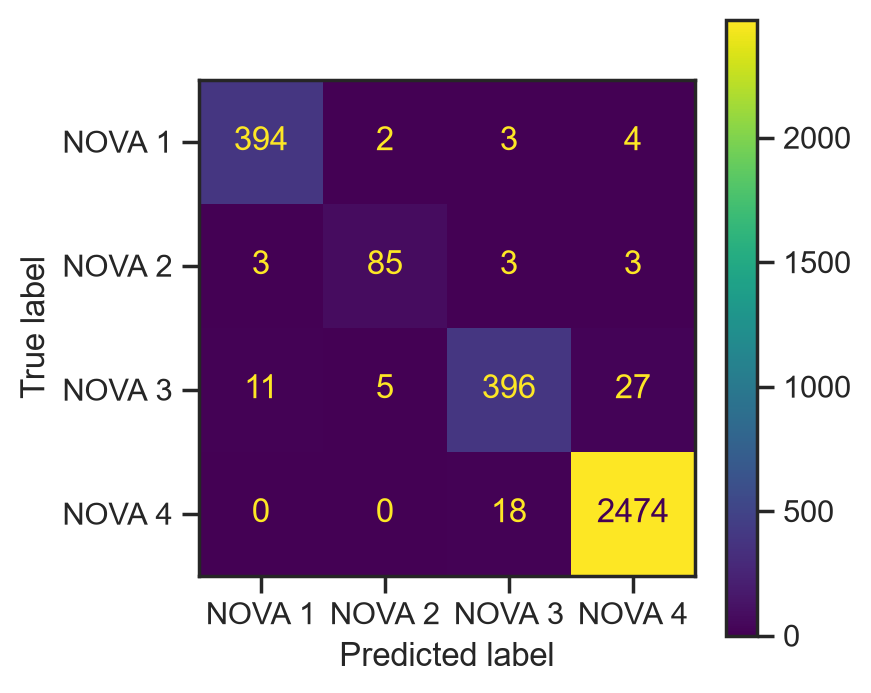

In [19]:
# Create a confusion matrix to compare the true NOVA classifications
# with the NOVA classifications predicted by the model
cm = confusion_matrix(
    y_true_nova,
    y_pred_nova,
    labels=[1, 2, 3, 4]
)

# Display the confusion matrix with NOVA groups labelled 1–4
# Rows represent the true NOVA group
# Columns represent the model's predicted NOVA group
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"]
)

# Plot the confusion matrix
disp.plot()

# Display the plot
plt.show()

# 2. Evaluate Model Performance Using FLIP2020 Data

In [20]:
# Prepare the 2020 dataset for NOVA prediction
# Keep only products with non-missing ingredient lists
# so that the 2017-trained model has text to classify.

data2020_predict = df2020.loc[
    df2020["Ingredients"].notna()
].copy()

print(
    "2020 products with ingredients:",
    data2020_predict.shape
)

2020 products with ingredients: (29608, 14)


In [21]:
# Clean 2020 ingredient text using the same preprocessing
# applied to the 2017 training data

data2020_predict["Ingredients"] = (
    data2020_predict["Ingredients"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

In [22]:
# Create Hugging Face dataset containing the 2020 ingredient text
# Use the same column name ("text") as the 2017 training dataset

predict2020 = Dataset.from_pandas(
    data2020_predict[["Ingredients"]].rename(
        columns={"Ingredients": "text"}
    ),
    preserve_index=False
)

In [23]:
# Tokenize 2020 ingredient lists using the same tokenizer used for model training

predict2020_tokenized = predict2020.map(
    tokenize_function,
    batched=True
)

Map: 100%|██████████| 29608/29608 [00:02<00:00, 10811.60 examples/s]


In [24]:
# Check tokenization worked

print(predict2020_tokenized.column_names)

['text', 'input_ids', 'token_type_ids', 'attention_mask']


In [25]:
# Generate NOVA predictions for 2020 using the model trained on 2017 data

predictions2020 = trainer1.predict(
    predict2020_tokenized
)

In [29]:
# Convert model labels (0–3) back to NOVA groups (1–4)

nova_pred_2020 = (
    predictions2020.predictions.argmax(axis=1) + 1
)

In [30]:
# Add predicted NOVA classification to the 2020 prediction dataset

data2020_predict["NOVA_predicted"] = nova_pred_2020

In [31]:
print("df2020:", "df2020" in globals())
print("data2020_predict:", "data2020_predict" in globals())
print("nova_pred_2020:", "nova_pred_2020" in globals())

df2020: True
data2020_predict: True
nova_pred_2020: True


In [32]:
# Create validation dataset for evaluating the 2017-trained model on FLIP 2020

validation2020 = data2020_predict.copy()

# Add manually validated NOVA classification from the original 2020 dataset

validation2020["NOVA_validated"] = df2020.loc[
    validation2020.index, "NOVA"
]

# Keep only products with both a manually validated and model-predicted NOVA classification

validation2020 = validation2020.loc[
    validation2020["NOVA_validated"].notna() &
    validation2020["NOVA_predicted"].notna()
].copy()

print(
    "Products available for validation:",
    len(validation2020)
)

Products available for validation: 28778


In [33]:
# Import metrics used to evaluate the 2017-trained model on the manually
# validated FLIP 2020 dataset

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate overall accuracy
# This is the proportion of 2020 products for which the model predicted
# the same NOVA group as the manually validated classification

accuracy2020 = accuracy_score(
    validation2020["NOVA_validated"],
    validation2020["NOVA_predicted"]
)

# Calculate balanced accuracy
# This gives equal weight to each NOVA group and accounts for differences
# in the number of products across NOVA groups

balanced_accuracy2020 = balanced_accuracy_score(
    validation2020["NOVA_validated"],
    validation2020["NOVA_predicted"]
)

print("2020 Accuracy:", round(accuracy2020, 3))
print("2020 Balanced Accuracy:", round(balanced_accuracy2020, 3))

2020 Accuracy: 0.933
2020 Balanced Accuracy: 0.879


In [34]:
# Calculate classification performance for each NOVA group
# This compares the model-predicted NOVA classification with the manually validated classification

print(
    classification_report(
        validation2020["NOVA_validated"],   # Manually validated NOVA classification (true value)
        validation2020["NOVA_predicted"],   # NOVA classification predicted by the model
        labels=[1, 2, 3, 4],                # Include all four NOVA groups
        target_names=["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"],
        digits=3                             # Report results to three decimal places
    )
)

              precision    recall  f1-score   support

      NOVA 1      0.901     0.961     0.930      4808
      NOVA 2      0.846     0.837     0.842       762
      NOVA 3      0.864     0.750     0.803      3850
      NOVA 4      0.956     0.966     0.961     19358

    accuracy                          0.933     28778
   macro avg      0.892     0.879     0.884     28778
weighted avg      0.932     0.933     0.932     28778



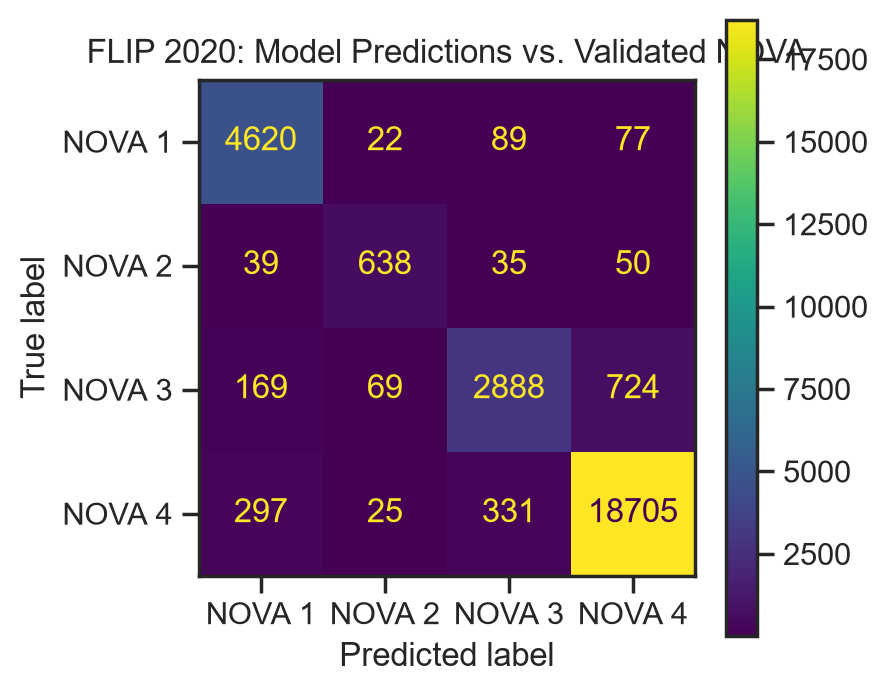

In [35]:
# Create a confusion matrix to compare manually validated NOVA classifications
# with NOVA classifications predicted by the model
# Rows represent the manually validated (true) NOVA group
# Columns represent the model's predicted NOVA group

cm2020 = confusion_matrix(
    validation2020["NOVA_validated"],   # Manually validated NOVA classification (true value)
    validation2020["NOVA_predicted"],   # NOVA classification predicted by the model
    labels=[1, 2, 3, 4]                  # Order the NOVA groups from 1 to 4
)

# Display the confusion matrix with NOVA groups labelled 1–4

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm2020,
    display_labels=["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"]
)

# Plot the confusion matrix

disp.plot()

# Add a title to describe the comparison

plt.title("FLIP 2020: Model Predictions vs. Validated NOVA")

# Display the plot

plt.show()

In [36]:
# Calculate overall model performance for the 2020 validation dataset
# This evaluates the model trained on validated 2017 data only

accuracy2020 = accuracy_score(
    validation2020["NOVA_validated"],
    validation2020["NOVA_predicted"]
)

balanced_accuracy2020 = balanced_accuracy_score(
    validation2020["NOVA_validated"],
    validation2020["NOVA_predicted"]
)

print("2020 validation sample size:", len(validation2020))
print("2020 accuracy:", round(accuracy2020, 3))
print("2020 balanced accuracy:", round(balanced_accuracy2020, 3))

2020 validation sample size: 28778
2020 accuracy: 0.933
2020 balanced accuracy: 0.879


In [37]:
# Identify products where the 2017-trained model's prediction differs
# from the manually validated NOVA classification

misclassified2020 = validation2020.loc[
    validation2020["NOVA_validated"] != validation2020["NOVA_predicted"]
].copy()

# Count the number and percentage of misclassified products

print("Number of misclassified products:", len(misclassified2020))
print(
    "Percentage misclassified:",
    round(len(misclassified2020) / len(validation2020) * 100, 1),
    "%"
)

Number of misclassified products: 1927
Percentage misclassified: 6.7 %


In [38]:
# Display examples of misclassified products

display(
    misclassified2020[
        ["Ingredients", "NOVA_validated", "NOVA_predicted"]
    ].head(20)
)

,Ingredients,NOVA_validated,NOVA_predicted
8,cut-up chicken pieces (breast with rib attache...,3.0,1
19,"pumpernickel bread (enriched wheat flour, wate...",4.0,1
21,"chicken wings ((drumettes, winglets), water, r...",4.0,3
47,"rolled oats, sweetened dried cranberries (cran...",3.0,4
50,"unbleached wheat flour, white cheddar cheese (...",3.0,4
52,"unbleached wheat flour, water, onions, white c...",3.0,4
116,"organic whole wheat flour, water, organic hone...",3.0,4
138,"concentrated grape juice, sugar, citric acid.",3.0,4
152,"pasteurized milk and cream, bacterial cultures...",4.0,3
171,"whole grain oats, whole grain wheat, raisins (...",4.0,3


In [39]:
# Summarize misclassifications by manually validated and predicted NOVA group

misclassification_summary2020 = pd.crosstab(
    misclassified2020["NOVA_validated"],
    misclassified2020["NOVA_predicted"]
)

print(misclassification_summary2020)

NOVA_predicted    1   2    3    4
NOVA_validated                   
1.0               0  22   89   77
2.0              39   0   35   50
3.0             169  69    0  724
4.0             297  25  331    0


In [40]:
# Check the distribution of manually validated NOVA classifications in FLIP 2020
# Missing values are included in the count

print(
    df2020["NOVA"]
    .value_counts(dropna=False)
    .sort_index()
)

NOVA
1.0     4877
2.0      765
3.0     3858
4.0    19396
NaN    19933
Name: count, dtype: int64


In [41]:
# Create a copy of the complete original 2020 dataset
# The existing NOVA column contains the manually validated classifications

results2020 = df2020.copy()

# Create a blank column for the model predictions

results2020["NOVA_predicted"] = pd.NA

# Add model-predicted NOVA classifications for products with ingredients

results2020.loc[
    data2020_predict.index,
    "NOVA_predicted"
] = nova_pred_2020

# Convert predicted NOVA classifications to numeric

results2020["NOVA_predicted"] = pd.to_numeric(
    results2020["NOVA_predicted"],
    errors="coerce"
)

In [42]:
# Check that the final datasets contain the same number of products
# as their respective original datasets

print("2020:", df2020.shape, "→", results2020.shape)

2020: (48829, 14) → (48829, 15)


In [43]:
# Check manually validated and model-predicted NOVA classifications in FLIP 2020

print("\n2020 validated NOVA:")
print(
    results2020["NOVA"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\n2020 predicted NOVA:")
print(
    results2020["NOVA_predicted"]
    .value_counts(dropna=False)
    .sort_index()
)


2020 validated NOVA:
NOVA
1.0     4877
2.0      765
3.0     3858
4.0    19396
NaN    19933
Name: count, dtype: int64

2020 predicted NOVA:
NOVA_predicted
1.0     5241
2.0      765
3.0     3397
4.0    20205
NaN    19221
Name: count, dtype: int64


In [ ]:
# Save the 2020 validation dataset as an Excel file
# This contains both the manually validated NOVA and the
# predictions from the model trained on 2017 data

results2020.to_excel(
    "data/flip2020_NOVA_validated_and_predicted.xlsx",
    index=False
)

2020 validation file saved successfully.


# 3. Develop the Final Model Using Validated FLIP2017 and FLIP2020 Data

In [ ]:
# Use the cleaned and manually validated 2017 data
final2017 = df2017b.copy()

print("Validated 2017 products:", len(final2017))

Validated 2017 products: 17137


In [47]:
# Use the cleaned 2020 ingredient data and manually validated NOVA classifications
# for final model training
final2020 = data2020_predict[["Ingredients"]].copy()

# Add the manually validated NOVA classification from the original 2020 dataset
final2020["NOVA"] = df2020.loc[
    final2020.index,
    "NOVA"
]

# Keep only products with a manually validated NOVA classification
final2020 = final2020.loc[
    final2020["NOVA"].notna()
].copy()

# Rename variables to match the 2017 training dataset
final2020 = final2020.rename(
    columns={
        "Ingredients": "text",
        "NOVA": "label"
    }
)

# Convert NOVA 1–4 to model labels 0–3
final2020["label"] = (
    pd.to_numeric(final2020["label"], errors="coerce") - 1
).astype(int)

print("Validated 2020 products:", len(final2020))

Validated 2020 products: 28778


In [48]:
# Combine all manually validated 2017 and 2020 products
# These data will be used to train the final NOVA classification model
final_training_data = pd.concat(
    [final2017, final2020],
    ignore_index=True
)

# Check the total number of training observations
print(
    "Total training observations:",
    len(final_training_data)
)

# Check the distribution of model labels
# Labels 0–3 correspond to NOVA groups 1–4
print("\nCombined model label distribution:")
print(
    final_training_data["label"]
    .value_counts()
    .sort_index()
)

Total training observations: 45915

Combined model label distribution:
label
0     6824
1     1233
2     6042
3    31816
Name: count, dtype: int64


In [49]:
# Create Hugging Face dataset for final model training
final_train_dataset = Dataset.from_pandas(
    final_training_data,
    preserve_index=False
)

# Tokenize the combined validated dataset using the same tokenizer
# and tokenization function used for the original model
final_tokenized_dataset = final_train_dataset.map(
    tokenize_function,
    batched=True
)

Map: 100%|██████████| 45915/45915 [00:04<00:00, 10836.48 examples/s]


In [50]:
# Load a fresh copy of the pre-trained model
# This ensures the final model starts from the original pre-trained weights
# rather than continuing training the 2017-only model
final_model = AutoModelForSequenceClassification.from_pretrained(
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
    num_labels=4
)

# Set training parameters
# No evaluation dataset is specified because this model is being trained
# using all manually validated 2017 and 2020 data for final prediction
final_training_args = TrainingArguments(
    disable_tqdm=False,
    output_dir="./final_nova_model",
    num_train_epochs=10
)

# Create Trainer for the final model
final_trainer = Trainer(
    model=final_model,
    args=final_training_args,
    train_dataset=final_tokenized_dataset
)

# Train the final model using all manually validated 2017 and 2020 data
final_trainer.train()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11559.19it/s]


Step,Training Loss
500,0.430007
1000,0.232878
1500,0.212585
2000,0.182653
2500,0.201495
3000,0.205213
3500,0.198074
4000,0.173007
4500,0.183835
5000,0.178157


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 13.33it/s]


TrainOutput(global_step=57400, training_loss=0.09218984957771434, metrics={'train_runtime': 2888.6453, 'train_samples_per_second': 158.95, 'train_steps_per_second': 19.871, 'total_flos': 1.52291675990016e+16, 'train_loss': 0.09218984957771434, 'epoch': 10.0})

In [51]:
# Prepare 2023 data for final NOVA prediction
# Keep only products with non-missing ingredient lists

data2023_predict = df2023.loc[
    df2023["Ingredients"].notna()
].copy()

# Clean ingredient text using the same preprocessing applied to the training data

data2023_predict["Ingredients"] = (
    data2023_predict["Ingredients"]
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

print("2023 products with ingredients:", data2023_predict.shape)

2023 products with ingredients: (100486, 15)


In [52]:
# Create Hugging Face dataset using the same column name ("text")
# as the model training dataset

final_predict2023 = Dataset.from_pandas(
    data2023_predict[["Ingredients"]].rename(
        columns={"Ingredients": "text"}
    ),
    preserve_index=False
)

In [53]:
# Tokenize the 2023 ingredient lists
final_predict2023_tokenized = final_predict2023.map(
    tokenize_function,
    batched=True
)

# Generate predictions using the final model
final_predictions2023 = final_trainer.predict(
    final_predict2023_tokenized
)

# Convert model labels 0–3 back to NOVA groups 1–4
final_nova_pred_2023 = (
    final_predictions2023.predictions.argmax(axis=1) + 1
)

Map: 100%|██████████| 100486/100486 [00:08<00:00, 11212.94 examples/s]


In [ ]:
# Create the complete 2023 dataset with final model-predicted NOVA
final_results2023 = df2023.copy()

# Create a blank column for the model predictions
final_results2023["NOVA_predicted"] = pd.NA

# Add final model predictions for products with ingredient lists
final_results2023.loc[
    data2023_predict.index,
    "NOVA_predicted"
] = final_nova_pred_2023

# Convert predicted NOVA classifications to numeric
final_results2023["NOVA_predicted"] = pd.to_numeric(
    final_results2023["NOVA_predicted"],
    errors="coerce"
)

# Save the 2023 NOVA predictions in an Excel file 
final_results2023.to_excel(
    "data/flip2023_NOVA_predicted.xlsx",
    index=False
)

In [57]:
# Check the predicted NOVA distribution from the final model

print("\n2023 final NOVA distribution:")
print(
    final_results2023["NOVA_predicted"]
    .value_counts(dropna=False)
    .sort_index()
)


2023 final NOVA distribution:
NOVA_predicted
1.0    17142
2.0     2319
3.0    10973
4.0    70052
NaN    10095
Name: count, dtype: int64
